# 01 · Integración y calidad de los datos

Este notebook une los archivos anuales de Estadísticas Policiales del OIJ, revisa su calidad y genera la tabla base del proyecto: **delitos por cantón, mes y tipo de delito**.

**Fuente:** [Portal de Datos Abiertos del Poder Judicial](https://datosabiertospj.poder-judicial.go.cr/dataset/estadisticas-policiales), licencia Creative Commons Attribution.

Para obtener todos los años: `python scripts/descargar_oij.py`.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import matplotlib.pyplot as plt

from src import oij

pd.set_option('display.width', 120)

## 1. Carga de todos los años disponibles

In [2]:
df = oij.cargar_todos(RAIZ / 'data' / 'raw')
resumen = df.groupby(['Anio', 'Archivo']).agg(registros=('Delito', 'size'),
                                              desde=('Fecha', 'min'), hasta=('Fecha', 'max'))
resumen

,,registros,desde,hasta
Anio,Archivo,,,
2015,PJCROD_POLICIALES_V1-2015.xls,54933,2015-01-01,2015-12-31
2016,PJCROD_POLICIALES_V1-2016.xls,58561,2016-01-01,2016-12-31
2017,PJCROD_POLICIALES_V1-2017.xls,59414,2017-01-01,2017-12-31
2018,PJCROD_POLICIALES_V1-2018.xls,61464,2018-01-01,2018-12-31
2019,PJCROD_POLICIALES_V1-2019.xlsx,58044,2019-01-01,2019-12-31
2020,PJCROD_POLICIALES_V1-2020.xlsx,38758,2020-01-01,2020-12-31
2021,PJCROD_POLICIALES_V1-2021.xlsx,40219,2021-01-01,2021-12-31
2022,PJCROD_POLICIALES_V1-2022.xlsx,48630,2022-01-01,2022-12-31
2023,PJCROD_POLICIALES_V1-2023.xlsx,48037,2023-01-01,2023-12-31


**Versiones de archivo:** de 2019 a 2024 el portal publica el mismo año en XLS y en XLSX. El XLSX es la versión más reciente y completa (por ejemplo, el XLS de 2023 solo llega al 30 de agosto), así que la carga usa el XLSX cuando existen ambos. Esto indica además que el OIJ actualiza los años ya publicados con denuncias tardías.

### Delitos por año y tipo

In [3]:
anual = pd.crosstab(df['Anio'], df['Delito'])
anual['TOTAL'] = anual.sum(axis=1)
anual

Delito,ASALTO,HOMICIDIO,HURTO,ROBO,ROBO DE VEHICULO,TACHA DE VEHICULO,TOTAL
Anio,,,,,,,
2015,14712,575,19206,11779,3897,4764,54933
2016,16983,627,19513,11771,4283,5384,58561
2017,17722,658,18519,11910,4964,5641,59414
2018,19461,642,17791,12614,5123,5833,61464
2019,18273,623,17732,12322,4580,4514,58044
2020,11332,625,11133,9254,3217,3197,38758
2021,10862,650,12803,9287,3438,3179,40219
2022,12704,732,15989,10729,4571,3905,48630
2023,12659,1008,15840,9853,4819,3858,48037


## 2. Perfil de calidad

Porcentaje de valores vacíos o desconocidos por columna.

In [4]:
oij.perfil_calidad(df)

,columna,categorias,pct_vacio_o_desconocido
0,Delito,6,0.00
1,SubDelito,40,0.07
2,Fecha,4299,0.00
3,Victima,4,0.00
4,SubVictima,84,0.00
5,Edad,4,6.04
6,Genero,1,100.00
7,Nacionalidad,157,5.16
8,Provincia,8,0.00
9,Canton,82,0.23


**Lectura:**

- Fecha, delito y ubicación están prácticamente completas: son las variables clave del modelo.
- `Genero` está vacía en todos los registros, así que se descarta.
- No existe columna de hora: el análisis temporal se hace por día, mes y día de la semana.

## 3. Filas idénticas

No hay un identificador de caso, así que las filas repetidas pueden ser varias víctimas de un mismo hecho. Se conservan y se documenta su volumen.

In [5]:
dup = df.duplicated(subset=oij.COLUMNAS).groupby(df['Anio']).mean().mul(100).round(1)
dup.rename('% filas idénticas').to_frame()

,% filas idénticas
Anio,
2015,6.1
2016,7.4
2017,7.6
2018,8.4
2019,8.4
2020,6.9
2021,6.6
2022,7.6
2023,7.8


## 4. Armonización de cantones

Río Cuarto (2017), Monteverde (2021) y Puerto Jiménez (2022) se crearon dentro del periodo. Se reasignan a su cantón de origen para que las series sean comparables.

In [6]:
cambios = df[df['Canton_original'] != df['Canton']]
cambios.groupby(['Canton_original', 'Canton']).size().rename('registros').to_frame()

,,registros
Canton_original,Canton,
MONTEVERDE,PUNTARENAS,674
PUERTO JIMENEZ,GOLFITO,1192
RIO CUARTO,GRECIA,630


In [7]:
print('Cantones tras armonizar:', df.loc[~df['Canton'].isin(oij.VALORES_DESCONOCIDOS), 'Canton'].nunique())

Cantones tras armonizar: 81


## 5. Tabla base: delitos por cantón, mes y tipo

Se excluyen los registros sin cantón conocido y el mes en curso (incompleto). La rejilla incluye ceros para las combinaciones sin delitos.

In [8]:
base = oij.agregar_mensual(df)
print(base.shape)
print('Meses:', base['Mes'].min(), '→', base['Mes'].max())
base.head()

(68526, 5)
Meses: 2015-01 → 2026-09


,Provincia,Canton,Mes,Delito,Delitos
0,GUANACASTE,ABANGARES,2015-01,HURTO,4
1,GUANACASTE,ABANGARES,2015-01,ASALTO,0
2,GUANACASTE,ABANGARES,2015-01,ROBO,5
3,GUANACASTE,ABANGARES,2015-01,ROBO DE VEHICULO,1
4,GUANACASTE,ABANGARES,2015-01,TACHA DE VEHICULO,1


In [9]:
fuera = df['Canton'].isin(oij.VALORES_DESCONOCIDOS).sum()
print(f'Registros sin cantón conocido excluidos: {fuera} ({100*fuera/len(df):.2f} %)')
print('Último mes completo:', oij.ultimo_mes_completo(df))

Registros sin cantón conocido excluidos: 1328 (0.23 %)
Último mes completo: 2026-09


## 6. Primera mirada: total nacional por tipo de delito

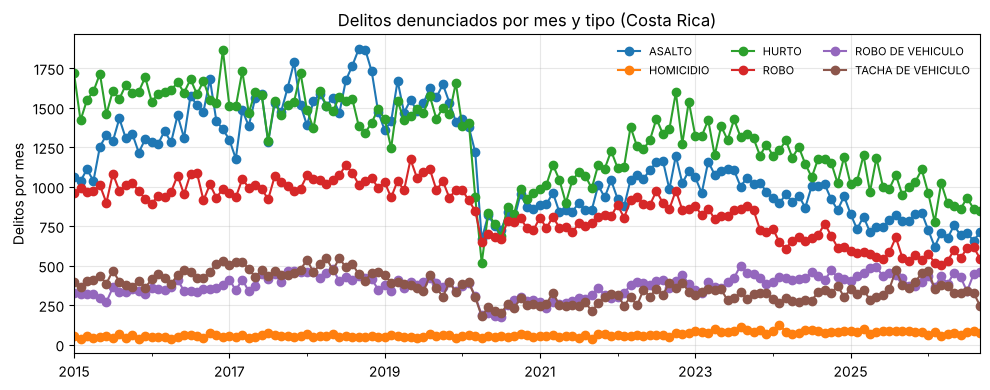

In [10]:
nacional = base.groupby(['Mes', 'Delito'])['Delitos'].sum().unstack()
fig, ax = plt.subplots(figsize=(10, 4))
nacional.plot(ax=ax, marker='o', lw=1.5)
ax.set_ylabel('Delitos por mes'); ax.set_xlabel('')
ax.set_title('Delitos denunciados por mes y tipo (Costa Rica)')
ax.legend(ncol=3, fontsize=8, frameon=False)
ax.grid(alpha=.3)
plt.tight_layout()
fig.savefig(RAIZ / 'reports' / 'figures' / '01_total_mensual_por_delito.png', dpi=150)

## 7. Guardar

In [11]:
salida = RAIZ / 'data' / 'processed' / 'delitos_canton_mes.parquet'
base.assign(Mes=base['Mes'].astype(str)).to_parquet(salida, index=False)
print('Guardado en', salida)

Guardado en /home/claude/tfm---isaac-sanchez/data/processed/delitos_canton_mes.parquet
